This is my notebook :)

/home/Julian/miniforge3/envs/Amuse-env/lib/python3.14/site-packages/amuse/ext/orbital_elements.py:344: UserWarning: new_binary_from_orbital_elements is deprecated, use generate_binaries instead
  warnings.warn(


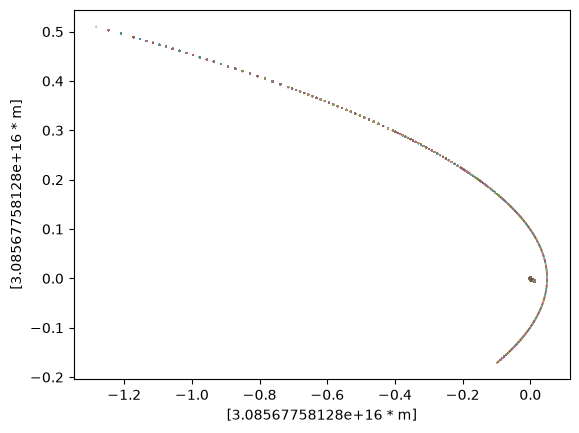

In [4]:
from amuse.lab import *
from amuse.ext.orbital_elements import new_binary_from_orbital_elements
import numpy as np

from amuse.community.ph4.interface import Ph4
from amuse.plot import scatter
import matplotlib.pyplot as plt

"""
This file governs the gravity of the gravity part of the simulation. This should create the two black holes, 
"""

class grav():
    def __init__(self,Mcentral):
        """
        This file should create empty containers for point masses for use in the gravity. These will be populated by the following functions and 
        used to create a gravitational simulation in further phases.
        """

        self.Mass_central_bh=Mcentral
        pass

    def create_black_hole(self,orbelem,mass_bh):
        """
        Creates a black hole with the specified properties

        Args:
            orbelem: The orbital elements of the incoming black hole (with a and e)
            mass_bh: the mass of the incominb black hole
        """

        self.bodies = new_binary_from_orbital_elements(self.Mass_central_bh,mass_bh,orbelem[0],orbelem[1],240)
        self.bodies.name = ["Central black hole", "Incoming black hole"]


    def setup_grav_simulation(self):
        """
        todo setup gravity simulation.
        """

        converter = nbody_system.nbody_to_si(self.bodies.mass.sum(),1|units.pc)
        gravity = Ph4(converter)
        gravity.parameters.timestep_parameter = 0.1
        gravity.particles.add_particles(self.bodies)

        self.channel_from_gravity = gravity.particles.new_channel_to(self.bodies)
        self.gravity = gravity

        return

    def propagate_grav_simulation(self,dt,tend):
        """
        Todo do a part of the gravity simulation
        """
        time = 0|units.yr
        while self.gravity.model_time < tend:
            time += dt
            self.gravity.evolve_model(time)
            self.channel_from_gravity.copy()
            scatter(self.bodies.x,self.bodies.y,s=np.sqrt(self.bodies.mass/self.bodies.mass.sum()))

        plt.show()
        
        self.gravity.stop

if __name__ == "__main__":
    """
    This block of code only runs if this file specifically is ran, not if this code is imported from another module.
    Use this to test whether everything is working properly and test your code independently of the rest.
    """

    grav_sim = grav(1e5|units.Msun)
    grav_sim.create_black_hole([50|units.pc,0.999],1e3|units.Msun)

    grav_sim.setup_grav_simulation()
    grav_sim.propagate_grav_simulation(10|units.yr,40000|units.yr)